# Munich rents: distributional modelling

A conditional rent distribution supplies a median and prediction intervals
for apartments with specified characteristics. This study fits Gaussian
location-scale models to log monthly rent and compares a constant residual
scale with a scale that varies with floor area and construction year. It
evaluates the complete choice of specification and stopping point by holding
out districts, then saves and reloads one fitted model.

The response is the rent recorded in the 1999 survey. The fitted distribution
describes rents paid at that time; it gives neither a recommended price nor the
effect of renovating an apartment. The same survey is analysed for spatial
district effects in [](munich_rents.ipynb) and through a sequence of
specification changes in [](working_a_model.ipynb).

Nested grouped validation chooses the scale specification and the stopping
point; the selected model then returns rent intervals and is saved as a
reusable file.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | a predictive rent distribution for apartments in districts excluded from fitting |
| **Observed response** | monthly net rent in the 1999 Munich survey |
| **Estimand** | conditional quantiles of historical rent given apartment characteristics, evaluated on unseen districts |
| **Units** | euros per month; log rent means the natural log of rent divided by one euro |
| **Sampling unit** | one apartment |
| **Dependence** | apartments share districts; adjacent districts may remain dependent |
| **Split / resampling unit** | whole districts in five outer folds and three inner folds |
| **Tuning** | inner-fold joint negative log likelihood selects one of two scale specifications and a stopping point at which location and scale receive the same number of updates |
| **Uncertainty** | a district bootstrap of fixed outer predictions describes evaluation variability, conditional on the fitted procedures |
| **Claim type** | predictive performance for the stated historical population and split design |
:::


## Data and predictors

`munich_rent()` supplies the 3,082 apartments distributed as `rent99` in
`gamlss.data`. The [upstream data reference](https://search.r-project.org/CRAN/refmans/gamlss.data/html/rent99.html)
specifies euros for rent, square metres for floor area, and `cheating` as the
central-heating indicator. The dataset loader and the upstream reference both report euros; no currency conversion
is applied here.

`rentsqm` is rent divided by area and therefore contains the response; it is
excluded. Location quality is represented by two indicators relative to
average quality. Construction year, amenities and location quality are
assumed available when a prediction is requested. District codes define the
validation groups, and do not enter as numerical predictors.

In [1]:
import json
import tempfile
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
from IPython.display import Markdown, display

import mboostrs as mb
from mboostrs import plot as mbplot

# SVG charts can be embedded in both the HTML and PDF editions of the book.
alt.renderers.enable("svg")

RendererRegistry.enable('svg')

In [2]:
raw = mb.datasets.munich_rent(output="polars")

# Exclude rentsqm: it is calculated from the response and would leak rent.
data = raw.select(
    "rent", "area", "yearc", "location", "bath", "kitchen", "cheating", "district",
)

# Fix these encodings before splitting; none estimates a value from outcomes.
data = data.with_columns(
    (pl.col("location") == 2).cast(pl.Int64).alias("good"),
    (pl.col("location") == 3).cast(pl.Int64).alias("top"),
)
assert data.null_count().sum_horizontal().item() == 0
assert (data["rent"] > 0).all()
display(data.select("rent", "area", "yearc").describe())

statistic,rent,area,yearc
"""count""",3082.0,3082.0,3082.0
"""null_count""",0.0,0.0,0.0
"""mean""",459.437179,67.374757,1956.306295
"""std""",195.656638,23.720446,22.308868
"""min""",40.512821,20.0,1918.0
"""25%""",322.0,51.0,1939.0
"""50%""",427.025635,65.0,1959.0
"""75%""",559.435913,81.0,1972.0
"""max""",1843.384644,160.0,1997.0


## Location and scale specifications

Let $Y$ denote monthly rent and $L=\log(Y/1\,\mathrm{euro})$.
The fitted model assumes $L\mid x\sim N(\mu(x),\sigma(x)^2)$.
The location predictor has smooth terms for area and construction year,
plus linear effects for the indicators. The alternative scale predictor
uses smooth terms for area and year; the baseline estimates a constant scale.
Every selected term is an association conditional on this specification.

The median rent is $\exp(\mu)$ euros, while its conditional mean is
$\exp(\mu+\sigma^2/2)$ euros. A central interval is obtained by exponentiating
the corresponding Gaussian quantiles. Thus `mu` on this fit is a mean log
rent, and exponentiating it does not produce a mean rent.

Both scale specifications include the term `1`: the estimated constant
that lets boosting move the average log scale off its starting value. In a
formula it names the intercept, as it does in R's `log_rent ~ 1`; one
coefficient is fitted on an implicit column of ones, and no constant column
is added to the data.

In [3]:
# The response transform is declared in the formula: the fit works on
# log(rent), and the model remembers the step, so intervals, PIT values and
# euro-scale scores below all come back on the original scale.
mu_formula = (
    "log(rent) ~ bbs(area, df=4) + bbs(yearc, df=4) + "
    "bols(good) + bols(top) + bols(bath) + bols(kitchen) + bols(cheating)"
)
specifications = {
    "constant scale": {
        "mu": mu_formula,
        "sigma": "log(rent) ~ 1",
    },
    "varying scale": {
        "mu": mu_formula,
        "sigma": "log(rent) ~ 1 + bbs(area, df=4) + bbs(yearc, df=4)",
    },
}

# The diagonal grid advances location and scale by the same cycle count.
grid = [[m, m] for m in (20, 40, 80, 160, 320, 640)]
display(Markdown("```json\n" + json.dumps(specifications, indent=2) + "\n```"))

```json
{
  "constant scale": {
    "mu": "log(rent) ~ bbs(area, df=4) + bbs(yearc, df=4) + bols(good) + bols(top) + bols(bath) + bols(kitchen) + bols(cheating)",
    "sigma": "log(rent) ~ 1"
  },
  "varying scale": {
    "mu": "log(rent) ~ bbs(area, df=4) + bbs(yearc, df=4) + bols(good) + bols(top) + bols(bath) + bols(kitchen) + bols(cheating)",
    "sigma": "log(rent) ~ 1 + bbs(area, df=4) + bbs(yearc, df=4)"
  }
}
```

## Validation by district

Each outer fold holds out whole districts. Inside its training portion,
three grouped folds select the stopping point for each scale specification.
The specification with the smaller inner risk supplies the selected procedure's
outer predictions. The stopping grid is diagonal: at each of its six points
(20, 40, 80, 160, 320 and 640) location and scale receive the same number of
updates, so all six are read from one boosting path per inner fold. Separate
stopping points for location and scale are not searched. The fits use L2
stabilization, which divides each parameter's negative gradient by its root mean
square before the base learners are fitted, so that the location and scale
parameters, whose gradients have different magnitudes, take steps of comparable
size. The setting is the same in every fit.

The comparison assumes a future district can be described by the observed
apartment characteristics. It does not estimate a new district's random
effect or integrate a fitted distribution over unknown group effects.
Geographic blocking would be needed for a task requiring greater separation
between training and prediction locations.

In [4]:
def tuned_fit(frame, specification, folds):
    """Fit and select stopping using only this outer fold's training rows."""
    fitted = mb.gamboostLSS(
        specification,
        frame,
        family=mb.GaussianLSS(),
        control=mb.boost_control(640, 0.1),
        stabilization="L2",
    )
    cv = fitted.cvrisk(folds=folds, grid=grid)

    # LSS truncation refits at the chosen budgets; it is not a cheap slice.
    selected = fitted.with_mstop(cv.optimal_mstop)
    return selected, cv


In [5]:
def score_rents(fit, held_out):
    """Evaluate the lognormal rent distribution on untouched apartments."""
    # The fit carries the response transform, so the evaluation scores
    # rent directly: the density already includes the change-of-variables
    # factor, and the interval bounds come back in euros.
    evaluation = mb.evaluate_distribution(
        fit, held_out, "rent", data_role="external", levels=(0.9,),
    )
    mu = evaluation.parameters["mu"]
    sigma = evaluation.parameters["sigma"]

    # Convert Gaussian log-rent quantiles to rent quantiles, in euros.
    lower = np.exp(mu - 1.6448536269514722 * sigma)
    upper = np.exp(mu + 1.6448536269514722 * sigma)
    rent = held_out["rent"].to_numpy()

    rent_log_score = evaluation.negative_log_score
    return held_out.select("district", "area", "rent").with_columns(
        pl.Series("log score", rent_log_score),
        pl.Series("covered", ((lower <= rent) & (rent <= upper)).astype(float)),
        pl.Series("width", upper - lower),
        pl.Series("pit", evaluation.pit),
    )


The outer loop keeps each district entirely in training or testing. The
scoring function `score_rents` returns, for each held-out apartment, its log score (the negative log predictive density of the observed rent; lower is better), whether the central 90% interval covers the observed rent, the interval
width in euros and the PIT value. The inner comparison chooses the
specification before `score_rents` receives the outer test frame. Both candidates are retained for comparison, while the
`inner-selected` rows below evaluate the procedure's actual choice.

In [6]:
outer = mb.grouped_folds(data["district"].to_numpy(), B=5, seed=2026)

fold_rows = []

evaluation_frames = []

representative = None


In [7]:
for fold in range(5):
    # Define the external test districts for this fold.
    is_test = np.asarray(outer)[:, fold] == 0
    train = data.filter(pl.Series(~is_test))
    test = data.filter(pl.Series(is_test))
    assert set(train["district"]).isdisjoint(set(test["district"]))

    inner = mb.grouped_folds(train["district"].to_numpy(), B=3, seed=410 + fold)
    candidates = {}

    # Tune both candidates on the same training-only folds.
    for name, specification in specifications.items():
        fit, cv = tuned_fit(train, specification, inner)
        candidates[name] = (fit, cv)
        fold_rows.append({
            "fold": fold + 1,
            "model": name,
            "mstop": cv.optimal_mstop[0],
            "inner log score": float(np.min(cv.aggregate)),
            "upper boundary": cv.at_boundary(),
        })

    chosen = min(candidates, key=lambda name: float(np.min(candidates[name][1].aggregate)))

    # Only now inspect the outer outcomes and record both candidates' scores.
    for name, (fit, cv) in candidates.items():
        evaluated = score_rents(fit, test).with_columns(
            pl.lit(fold + 1).alias("fold"),
            pl.lit(name).alias("model"),
            pl.lit(name == chosen).alias("selected"),
        )
        evaluation_frames.append(evaluated)

    if fold == 0:
        representative = (candidates[chosen][0], train, test, chosen)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamlss.py:4447: RuntimeWarning: the lowest cross-validated risk is at [640, 640], the largest budget in the grid, so the reported optimum is where the search stopped rather than where the risk turns. Extend the grid -- mb.diagonal_grid(1280, 2) -- and refit with a control whose mstop covers it.
  return entry(folds=folds if isinstance(folds, FoldScheme) else folds_matrix,


/var/folders/pr/mdlxf70n2rl6445yj_0b0wx40000gn/T/ipykernel_42551/3669887043.py:6: ExtrapolationWarning: 1 value(s) of 'rent' lie below its smallest training value 54.9231; log(rent) holds them there, so their effect is the one at the training minimum
  evaluation = mb.evaluate_distribution(


In [8]:
fold_table = pl.DataFrame(fold_rows)

evaluations = pl.concat(evaluation_frames)

selected_rows = evaluations.filter(pl.col("selected")).with_columns(
    pl.lit("inner-selected").alias("model"),
)

all_scores = pl.concat([evaluations, selected_rows])

display(fold_table)


fold,model,mstop,inner log score,upper boundary
1,"""constant scale""",160,0.269576,false
1,"""varying scale""",160,0.237755,false
2,"""constant scale""",160,0.235972,false
2,"""varying scale""",320,0.204997,false
3,"""constant scale""",640,0.244405,true
3,"""varying scale""",80,0.220185,false
4,"""constant scale""",160,0.238159,false
4,"""varying scale""",80,0.214719,false
5,"""constant scale""",160,0.225896,false
5,"""varying scale""",160,0.204572,false


The score table below uses negative log density on the original euro scale.
If $p_L$ is the fitted log-rent density, then
$p_Y(y)=p_L(\log y)/y$, so $-\log p_Y(y)=-\log p_L(\log y)+\log y$.
The fitted model carries the log transform of the response, so the
evaluation adds the change-of-variables term $\log y$ itself. Lower log scores
are better. Coverage measures the share of observed rents in the central 90%
interval; width measures that interval in euros per month. The intervals are
quantiles of the fitted lognormal distribution, so their coverage is close to
90% only to the extent that the fitted distribution is correct; no finite-sample
coverage guarantee applies.

In [9]:
# Average per apartment: the intended population weights apartments equally.
summary = all_scores.group_by("model").agg(
    pl.col("log score").mean(),
    pl.col("covered").mean().alias("90% coverage"),
    pl.col("width").mean().alias("mean width, euros"),
).sort("model")
display(summary)

constant_score = summary.filter(pl.col("model") == "constant scale")["log score"].item()
varying_score = summary.filter(pl.col("model") == "varying scale")["log score"].item()
comparison_sentence = (
    f"The varying-scale model changes mean outer log score by {varying_score - constant_score:+.4f} "
    "relative to constant scale; negative values favor varying scale."
)
selected_coverage = summary.filter(pl.col("model") == "inner-selected")["90% coverage"].item()
boundary_count = int(fold_table["upper boundary"].sum())

model,log score,90% coverage,"mean width, euros"
"""constant scale""",6.277624,0.908501,458.022088
"""inner-selected""",6.248917,0.91499,452.362076
"""varying scale""",6.248917,0.91499,452.362076


{eval}`comparison_sentence` The procedure selected inside each outer training
sample covers {eval}`f"{selected_coverage:.1%}"` of the held-out rents with its
nominal 90% intervals. The search reaches the boundary of the grid, its largest stopping point, in
{eval}`boundary_count` of its ten specification-specific fits. A fit at that
boundary, 640 updates per parameter, would indicate that the risk was still
falling at the end of the grid and that the optimum may lie beyond it.

## Evaluation uncertainty and calibration

The next calculation resamples districts, retaining all apartments within
each sampled district. Its percentile interval describes variation in mean
log score for the selected procedure, conditional on the recorded predictions.
It does not repeat fitting or account fully for the overlap between training
folds. Coverage by floor-area band and the probability integral transform (PIT), the fitted cumulative distribution function (CDF) evaluated at each outcome, check aspects of calibration
that aggregate coverage can hide.

In [10]:
# Resample districts as blocks, preserving the number of apartments in each.
group_scores = selected_rows.group_by("district").agg(
    pl.col("log score").sum().alias("total"),
    pl.len().alias("n"),
)
rng = np.random.default_rng(88)
draws = rng.integers(0, group_scores.height, size=(500, group_scores.height))
sampled_totals = group_scores["total"].to_numpy()[draws].sum(axis=1)
sampled_counts = group_scores["n"].to_numpy()[draws].sum(axis=1)
bootstrap = sampled_totals / sampled_counts
score_interval = np.quantile(bootstrap, [0.025, 0.975])

display(pl.DataFrame({
    "mean log score": [selected_rows["log score"].mean()],
    "bootstrap lower": [score_interval[0]],
    "bootstrap upper": [score_interval[1]],
}))

mean log score,bootstrap lower,bootstrap upper
6.248917,6.207303,6.294344


"area, square metres",apartments,90% coverage,"mean width, euros"
"""50–89""",1908,0.912474,441.350235
"""90 and above""",489,0.92638,720.349385
"""under 50""",685,0.913869,291.726748


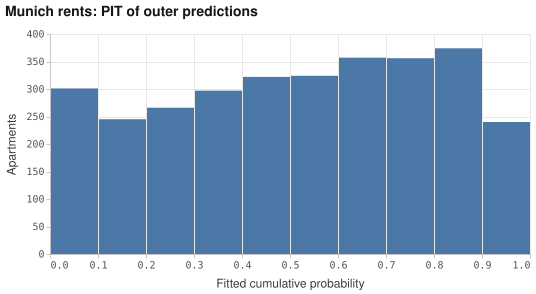

In [11]:
# Prespecified area bands expose coverage differences hidden by one average.
by_area = selected_rows.with_columns(
    pl.when(pl.col("area") < 50).then(pl.lit("under 50"))
    .when(pl.col("area") < 90).then(pl.lit("50–89"))
    .otherwise(pl.lit("90 and above")).alias("area, square metres")
).group_by("area, square metres").agg(
    pl.len().alias("apartments"),
    pl.col("covered").mean().alias("90% coverage"),
    pl.col("width").mean().alias("mean width, euros"),
).sort("area, square metres")
display(by_area)

pit_chart = alt.Chart(selected_rows).mark_bar().encode(
    x=alt.X("pit:Q", bin=alt.Bin(step=0.1), title="Fitted cumulative probability"),
    y=alt.Y("count():Q", title="Apartments"),
).properties(title="Munich rents: PIT of outer predictions", width=480, height=220)
display(pit_chart)

## Selected effects and prediction profiles

For illustration, the following tables and profile use the model selected
inside the first outer training sample. Update counts show which learners
the algorithm used for each parameter; they are not probabilities that an
association is real. The profile changes floor area while holding the other
characteristics at training-sample reference values. Its interval describes
individual rents under that profile, not confidence in the estimated curve.

In [12]:
# Inspect the first outer fit; it was not chosen by its test performance.
fit, train, test, chosen = representative
path = fit.path_frame(output="polars")
update_counts = path.group_by("parameter", "learner").len(name="updates")
display(update_counts.sort("parameter", "updates", descending=[False, True]))

# Hold other characteristics at training reference values while varying area.
area_values = np.linspace(
    float(train["area"].quantile(.05)), float(train["area"].quantile(.95)), 80,
)
reference_columns = {}
for name in ("yearc", "good", "top", "bath", "kitchen", "cheating"):
    reference_columns[name] = np.repeat(float(train[name].median()), len(area_values))

profile = pl.DataFrame(reference_columns).with_columns(pl.Series("area", area_values))
parameters = fit.predict(newdata=profile, type="response")
profile = profile.with_columns(
    pl.Series("median", np.exp(parameters["mu"])),
    pl.Series("lower", np.exp(parameters["mu"] - 1.6448536269514722 * parameters["sigma"])),
    pl.Series("upper", np.exp(parameters["mu"] + 1.6448536269514722 * parameters["sigma"])),
)

parameter,learner,updates
"""mu""","""area""",59
"""mu""","""yearc""",34
"""mu""","""cheating""",25
"""mu""","""good""",17
"""mu""","""top""",10
"""mu""","""kitchen""",9
"""mu""","""bath""",6
"""sigma""","""area""",83
"""sigma""","""yearc""",77


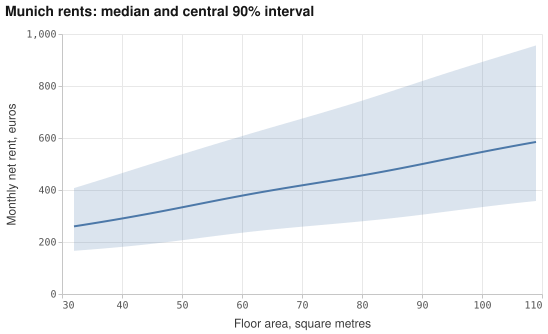

In [13]:
# The band describes individual rents, not uncertainty about the median curve.
base = alt.Chart(profile).encode(x=alt.X("area:Q", title="Floor area, square metres"))
band = base.mark_area(opacity=.2).encode(
    y=alt.Y("lower:Q", title="Monthly net rent, euros"), y2="upper:Q",
)
line = base.mark_line().encode(y="median:Q")
display((band + line).properties(
    title="Munich rents: median and central 90% interval", width=480, height=260,
))

profile_sentence = (
    f"Across the displayed area range, the predicted median changes from {profile['median'][0]:.0f} "
    f"to {profile['median'][-1]:.0f} euros per month under the {chosen} specification."
)

{eval}`profile_sentence` Larger apartments would ordinarily be expected to
have higher total rents, but this profile also holds construction year and
amenities fixed and does not establish an effect of increasing floor area.
Differences associated with construction year can represent building quality,
renovation and regulation as well as age. Amenity indicators may also proxy
unrecorded quality. The fitted scale combines unexplained apartment variation
with location information omitted from the specification.

## Extension: saving and scoring

`save_model` writes the fitted model to a versioned JSON file, and
`load_model` reconstructs a Python model from it. The check compares every
location and scale prediction before and after loading.

The file saved here is a full training checkpoint. It retains the training
frame and the settings a refit needs, so the loaded model supports `update`
(refit with changed data or arguments) and `with_mstop` (refit at a different
number of boosting iterations).

`save_model(..., scoring_only=True)` writes a smaller file that keeps only what
prediction reads. The response column is removed from the stored frame, and the
loaded model predicts but raises an error when `update` or `with_mstop` is
called.

The R package's `load_model` reads distributional (LSS: location, scale and
shape) files for inspection, reporting parameter names, the number of updates
per parameter and the offsets. It computes predictions only for linear
`glmboost` models; predicting from this model requires the Python
`load_model`.

In [14]:
# Archive this fitted model, then verify predictions through the public reader.
before = fit.predict(newdata=test, type="response")
with tempfile.TemporaryDirectory() as directory:
    artifact = mb.save_model(fit, Path(directory) / "munich-log-rent.json")
    artifact_bytes = artifact.stat().st_size
    restored = mb.load_model(artifact)

after = restored.predict(newdata=test, type="response")
differences = []
for parameter in before:
    np.testing.assert_allclose(before[parameter], after[parameter], rtol=1e-12, atol=1e-12)
    differences.append(float(np.max(np.abs(before[parameter] - after[parameter]))))

max_difference = max(differences)
display(pl.DataFrame({
    "artifact bytes": [artifact_bytes],
    "maximum prediction difference": [max_difference],
}))

artifact bytes,maximum prediction difference
662955,0.0


## Conclusions and limitations

The analysis produces an evaluated procedure for choosing a scale
specification, interpretable parameter predictors, and a saved file from
which the reloaded Python model reproduces the predictions exactly. The varying
scale improves the mean outer log score by 0.029 over a constant scale, and the
inner comparison selects it in all five folds. The five folds
partition one historical survey; they do not establish performance on another
city, another survey year, or today's rents. The analyst has also restricted
the family to a lognormal rent distribution and searched only a diagonal
stopping grid. Heavy tails, further geographic structure and independent
calibration data could change the assessment.

See [](distributional_comparison.ipynb) for comparisons with other libraries,
[](specification_search_validation.ipynb) for repeated evaluation of search,
and [](../usage/gamboostlss.ipynb) for the API.